## Part I: Data Pre-processing

In [1]:
import pandas as pd

In [ ]:
# Download the Google Analogy dataset
!wget http://download.tensorflow.org/data/questions-words.txt

In [2]:
# Preprocess the dataset
file_name = "questions-words"
with open(f"{file_name}.txt", "r") as f:
    data = f.read().splitlines()

In [3]:
# check data from the first 10 entries
for entry in data[:10]:
    print(entry)

: capital-common-countries
Athens Greece Baghdad Iraq
Athens Greece Bangkok Thailand
Athens Greece Beijing China
Athens Greece Berlin Germany
Athens Greece Bern Switzerland
Athens Greece Cairo Egypt
Athens Greece Canberra Australia
Athens Greece Hanoi Vietnam
Athens Greece Havana Cuba


In [4]:
# TODO1: Write your code here for processing data to pd.DataFrame
# Please note that the first five mentions of ": " indicate `semantic`,
# and the remaining nine belong to the `syntatic` category.

from pathlib import Path
import pandas as pd

txt_path = Path("questions-words.txt")

questions = []
sub_categories = []
category_order = []

current_subcat = None
with txt_path.open() as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        if line.startswith(":"):
            current_subcat = line
            if current_subcat not in category_order:
                category_order.append(current_subcat)
        else:
            questions.append(line)
            sub_categories.append(current_subcat)

semantic_subcats = set(category_order[:5])
categories = [
    "Semantic" if subcat in semantic_subcats else "Syntactic"
    for subcat in sub_categories
]

In [5]:
# Create the dataframe
df = pd.DataFrame(
    {
        "Question": questions,
        "Category": categories,
        "SubCategory": sub_categories,
    }
)

In [6]:
df.head()

,Question,Category,SubCategory
0,Athens Greece Baghdad Iraq,Semantic,: capital-common-countries
1,Athens Greece Bangkok Thailand,Semantic,: capital-common-countries
2,Athens Greece Beijing China,Semantic,: capital-common-countries
3,Athens Greece Berlin Germany,Semantic,: capital-common-countries
4,Athens Greece Bern Switzerland,Semantic,: capital-common-countries


In [7]:
df.to_csv(f"{file_name}.csv", index=False)

## Part II: Use pre-trained word embeddings
- After finish Part I, you can run Part II code blocks only.

In [9]:
import pandas as pd
import numpy as np
import gensim.downloader
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

In [10]:
data = pd.read_csv("questions-words.csv")

In [11]:
MODEL_NAME = "glove-wiki-gigaword-100"
# You can try other models.
# https://radimrehurek.com/gensim/models/word2vec.html#pretrained-models

# Load the pre-trained model (using GloVe vectors here)
model = gensim.downloader.load(MODEL_NAME)
print("The Gensim model loaded successfully!")

[==================================================] 100.0% 128.1/128.1MB downloaded
The Gensim model loaded successfully!


In [12]:
from gensim.models.keyedvectors import KeyedVectors

# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []

for analogy in tqdm(data["Question"]):
      # TODO2: Write your code here to use pre-trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """
      word_a, word_b, word_c, word_d = [w.lower() for w in analogy.split()]
      golds.append(word_d)

      if any(
            word not in model.key_to_index
            for word in (word_a, word_b, word_c)
      ):
            preds.append(None)  # or word_d to ignore in scoring
            continue

      predicted = model.most_similar(
            positive=[word_b, word_c],
            negative=[word_a],
            topn=1,
      )[0][0]

      preds.append(predicted)

100%|██████████| 19544/19544 [01:36<00:00, 201.80it/s]


In [13]:
# Perform evaluations. You do not need to modify this block!!

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

golds_np, preds_np = np.array(golds), np.array(preds)
data = pd.read_csv("questions-words.csv")

# Evaluation: categories
for category in data["Category"].unique():
    mask = data["Category"] == category
    golds_cat, preds_cat = golds_np[mask], preds_np[mask]
    acc_cat = calculate_accuracy(golds_cat, preds_cat)
    print(f"Category: {category}, Accuracy: {acc_cat * 100}%")

# Evaluation: sub-categories
for sub_category in data["SubCategory"].unique():
    mask = data["SubCategory"] == sub_category
    golds_subcat, preds_subcat = golds_np[mask], preds_np[mask]
    acc_subcat = calculate_accuracy(golds_subcat, preds_subcat)
    print(f"Sub-Category{sub_category}, Accuracy: {acc_subcat * 100}%")

Category: Semantic, Accuracy: 65.3399481339497%
Category: Syntactic, Accuracy: 61.255269320843084%
Sub-Category: capital-common-countries, Accuracy: 93.87351778656127%
Sub-Category: capital-world, Accuracy: 88.94783377541998%
Sub-Category: currency, Accuracy: 14.203233256351039%
Sub-Category: city-in-state, Accuracy: 30.806647750304013%
Sub-Category: family, Accuracy: 81.62055335968378%
Sub-Category: gram1-adjective-to-adverb, Accuracy: 24.39516129032258%
Sub-Category: gram2-opposite, Accuracy: 20.073891625615765%
Sub-Category: gram3-comparative, Accuracy: 79.12912912912913%
Sub-Category: gram4-superlative, Accuracy: 54.278074866310156%
Sub-Category: gram5-present-participle, Accuracy: 69.50757575757575%
Sub-Category: gram6-nationality-adjective, Accuracy: 87.86741713570981%
Sub-Category: gram7-past-tense, Accuracy: 55.44871794871795%
Sub-Category: gram8-plural, Accuracy: 71.996996996997%
Sub-Category: gram9-plural-verbs, Accuracy: 58.39080459770115%


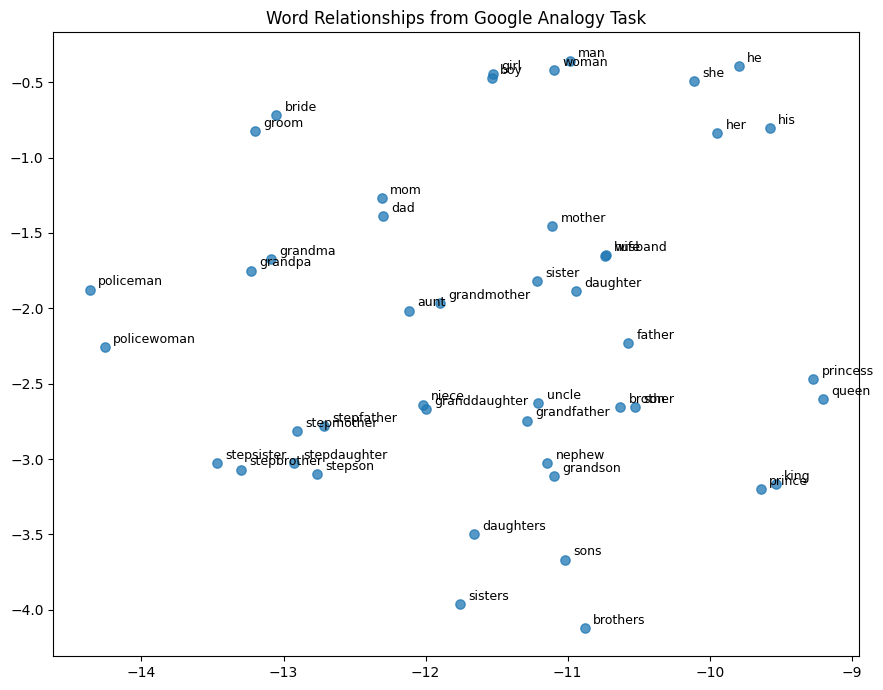

In [14]:
# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO3: Plot t-SNE for the words in the SUB_CATEGORY `: family`


from sklearn.manifold import TSNE

subset = data[data["SubCategory"] == SUB_CATEGORY]["Question"]

words = set()
for analogy in subset:
    words.update(token.lower() for token in analogy.split())

vectors, labels = [], []
missing = []
for word in sorted(words):
    if word in model.key_to_index:
        vectors.append(model[word])
        labels.append(word)
    else:
        missing.append(word)

if missing:
    print(f"Skipped {len(missing)} OOV words:", ", ".join(missing))

if len(vectors) < 2:
    raise ValueError("Not enough words with embeddings to plot t-SNE.")

vectors_np = np.vstack(vectors)
tsne = TSNE(
    n_components=2,
    perplexity=min(30, len(vectors_np) - 1),
    random_state=0,
    init="pca",
    learning_rate="auto",
)
coords = tsne.fit_transform(vectors_np)

plt.figure(figsize=(9, 7))
plt.scatter(coords[:, 0], coords[:, 1], s=45, alpha=0.75)

for (x, y), label in zip(coords, labels):
    plt.annotate(label, (x, y), textcoords="offset points", xytext=(6, 3), fontsize=9)

plt.title("Word Relationships from Google Analogy Task")
plt.tight_layout()
plt.savefig("word_relationships.png", bbox_inches="tight")
plt.show()

### Part III: Train your own word embeddings

### Get the latest English Wikipedia articles and do sampling.
- Usually, we start from Wikipedia dump (https://dumps.wikimedia.org/enwiki/latest/enwiki-latest-pages-articles.xml.bz2). However, the downloading step will take very long. Also, the cleaning step for the Wikipedia corpus ([`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus)) will take much time. Therefore, we provide cleaned files for you.

In [16]:
# Download the split Wikipedia files
# Each file contain 562365 lines (articles).
!gdown --id 1jiu9E1NalT2Y8EIuWNa1xf2Tw1f1XuGd -O wiki_texts_part_0.txt.gz
!gdown --id 1ABblLRd9HXdXvaNv8H9fFq984bhnowoG -O wiki_texts_part_1.txt.gz
!gdown --id 1z2VFNhpPvCejTP5zyejzKj5YjI_Bn42M -O wiki_texts_part_2.txt.gz
!gdown --id 1VKjded9BxADRhIoCzXy_W8uzVOTWIf0g -O wiki_texts_part_3.txt.gz
!gdown --id 16mBeG26m9LzHXdPe8UrijUIc6sHxhknz -O wiki_texts_part_4.txt.gz

/opt/homebrew/Caskroom/mambaforge/base/envs/nlp_hw1/lib/python3.12/site-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1jiu9E1NalT2Y8EIuWNa1xf2Tw1f1XuGd
From (redirected): https://drive.google.com/uc?id=1jiu9E1NalT2Y8EIuWNa1xf2Tw1f1XuGd&confirm=t&uuid=4b3ca4fa-fbf9-443d-b3ce-89f8d727884d
To: /Users/leonardo/Workspace/nthu-2025-fall-natural-language-processing/hw1/wiki_texts_part_0.txt.gz
100%|██████████████████████████████████████| 1.51G/1.51G [00:42<00:00, 35.7MB/s]
/opt/homebrew/Caskroom/mambaforge/base/envs/nlp_hw1/lib/python3.12/site-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?

In [17]:
# Download the split Wikipedia files
# Each file contain 562365 lines (articles), except the last file.
!gdown --id 17JFvxOH-kc-VmvGkhG7p3iSZSpsWdgJI -O wiki_texts_part_5.txt.gz
!gdown --id 19IvB2vOJRGlrYulnTXlZECR8zT5v550P -O wiki_texts_part_6.txt.gz
!gdown --id 1sjwO8A2SDOKruv6-8NEq7pEIuQ50ygVV -O wiki_texts_part_7.txt.gz
!gdown --id 1s7xKWJmyk98Jbq6Fi1scrHy7fr_ellUX -O wiki_texts_part_8.txt.gz
!gdown --id 17eQXcrvY1cfpKelLbP2BhQKrljnFNykr -O wiki_texts_part_9.txt.gz
!gdown --id 1J5TAN6bNBiSgTIYiPwzmABvGhAF58h62 -O wiki_texts_part_10.txt.gz

/opt/homebrew/Caskroom/mambaforge/base/envs/nlp_hw1/lib/python3.12/site-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=17JFvxOH-kc-VmvGkhG7p3iSZSpsWdgJI
From (redirected): https://drive.google.com/uc?id=17JFvxOH-kc-VmvGkhG7p3iSZSpsWdgJI&confirm=t&uuid=c0bba91f-53f9-4ba8-b64e-b86cb0b2591f
To: /Users/leonardo/Workspace/nthu-2025-fall-natural-language-processing/hw1/wiki_texts_part_5.txt.gz
100%|████████████████████████████████████████| 578M/578M [00:19<00:00, 30.1MB/s]
/opt/homebrew/Caskroom/mambaforge/base/envs/nlp_hw1/lib/python3.12/site-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?

In [18]:
# Extract the downloaded wiki_texts_parts files.
!gunzip -k wiki_texts_part_*.gz

In [19]:
# Combine the extracted wiki_texts_parts files.
!cat wiki_texts_part_*.txt > wiki_texts_combined.txt

In [20]:
# Check the first ten lines of the combined file
!head -n 10 wiki_texts_combined.txt

anarchism is political philosophy and movement that is against all forms of authority and seeks to abolish the institutions it claims maintain unnecessary coercion and hierarchy typically including the state and capitalism anarchism advocates for the replacement of the state with stateless societies and voluntary free associations as historically left wing movement this reading of anarchism is placed on the farthest left of the political spectrum usually described as the libertarian wing of the socialist movement libertarian socialism although traces of anarchist ideas are found all throughout history modern anarchism emerged from the enlightenment during the latter half of the th and the first decades of the th century the anarchist movement flourished in most parts of the world and had significant role in workers struggles for emancipation various anarchist schools of thought formed during this period anarchists have taken part in several revolutions most notably in the paris commune

Please note that we used the default parameters of [`gensim.corpora.wikicorpus.WikiCorpus`](https://radimrehurek.com/gensim/corpora/wikicorpus.html#gensim.corpora.wikicorpus.WikiCorpus) for cleaning the Wiki raw file. Thus, words with one character were discarded.

In [ ]:
# Now you need to do sampling because the corpus is too big.
# You can further perform analysis with a greater sampling ratio.

import random

wiki_txt_path = "wiki_texts_combined.txt"
output_path = "wiki_texts_sampled.txt"

# wiki_texts_combined.txt is a text file separated by linebreaks (\n).
# Each row in wiki_texts_combined.txt indicates a Wikipedia article.

random.seed(42)

with open(wiki_txt_path, "r", encoding="utf-8") as f:
    with open(output_path, "w", encoding="utf-8") as output_file:
    # TODO4: Sample `20%` Wikipedia articles
    # Write your code here
        for article in f:
            if random.random() < 0.2:
                output_file.write(article)


In [42]:
# TODO5: Train your own word embeddings with the sampled articles
# https://radimrehurek.com/gensim/models/word2vec.html#gensim.models.word2vec.Word2Vec
# Hint: You should perform some pre-processing before training.

from tqdm.auto import tqdm
from gensim.utils import simple_preprocess
from gensim.models import Word2Vec
from gensim.models.callbacks import CallbackAny2Vec
import os

sampled_corpus_path = "wiki_texts_sampled.txt"
model_path = "custom_word2vec.model"
vectors_path = "custom_word2vec.kv"


class ArticleIterable:
    def __init__(self, path, total=None, desc=None):
        self.path = path
        self.total = total
        self.desc = desc

    def __iter__(self):
        with open(self.path, "r", encoding="utf-8") as f:
            iterator = f if self.total is None else tqdm(
                f, total=self.total, desc=self.desc, leave=False
            )
            for line in iterator:
                tokens = simple_preprocess(line)
                if tokens:
                    yield tokens

    def with_progress(self, desc):
        return ArticleIterable(self.path, total=self.total, desc=desc)


def count_lines(path):
    with open(path, "r", encoding="utf-8") as f:
        return sum(1 for _ in f)


class EpochLogger(CallbackAny2Vec):
    def __init__(self, total_epochs):
        self.epoch = 0
        self.total = total_epochs

    def on_epoch_begin(self, model):
        print(f"Epoch {self.epoch + 1}/{self.total} 開始")

    def on_epoch_end(self, model):
        print(f"Epoch {self.epoch + 1}/{self.total} 結束")
        self.epoch += 1


total_articles = count_lines(sampled_corpus_path)
corpus = ArticleIterable(sampled_corpus_path, total=total_articles)

model = Word2Vec(
    vector_size=100,
    window=5,
    min_count=5,
    sg=1,
    negative=10,
    workers=os.cpu_count(),
    epochs=5,
)

logger = EpochLogger(model.epochs)

model.build_vocab(corpus.with_progress("Building vocab"))
model.train(
    corpus.with_progress("Training model"),
    total_examples=model.corpus_count,
    epochs=model.epochs,
    callbacks=[logger],
)

model.save(model_path)
model.wv.save(vectors_path)

print("Training complete.")
print(f"Vocabulary size: {len(model.wv)}")
print(f"Corpus count: {model.corpus_count}")
print(f"Total words seen: {model.corpus_total_words}")

Epoch 1/5 開始


Epoch 1/5 結束
Epoch 2/5 開始


Epoch 2/5 結束
Epoch 3/5 開始


Epoch 3/5 結束
Epoch 4/5 開始


Epoch 4/5 結束
Epoch 5/5 開始


Epoch 5/5 結束
Training complete.
Vocabulary size: 703054
Corpus count: 563148
Total words seen: 335376432


In [26]:
data = pd.read_csv("questions-words.csv")

In [27]:
# Do predictions and preserve the gold answers (word_D)
preds = []
golds = []

custom_model = Word2Vec.load(model_path)
custom_vectors = custom_model.wv

for analogy in tqdm(data["Question"]):
      # TODO6: Write your code here to use your trained word embeddings for getting predictions of the analogy task.
      # You should also preserve the gold answers during iterations for evaluations later.
      """ Hints
      # Unpack the analogy (e.g., "man", "woman", "king", "queen")
      # Perform vector arithmetic: word_b + word_c - word_a should be close to word_d
      # Source: https://github.com/piskvorky/gensim/blob/develop/gensim/models/keyedvectors.py#L776
      # Mikolov et al., 2013: big - biggest and small - smallest
      # Mikolov et al., 2013: X = vector(”biggest”) − vector(”big”) + vector(”small”).
      """
      word_a, word_b, word_c, word_d = [w.lower() for w in analogy.split()]
      golds.append(word_d)

      if any(word not in custom_vectors.key_to_index for word in (word_a, word_b, word_c)):
            preds.append(None)
            continue

      prediction = custom_vectors.most_similar(
            positive=[word_b, word_c], negative=[word_a], topn=1
      )[0][0]
      preds.append(prediction)

100%|██████████| 19544/19544 [04:58<00:00, 65.48it/s]


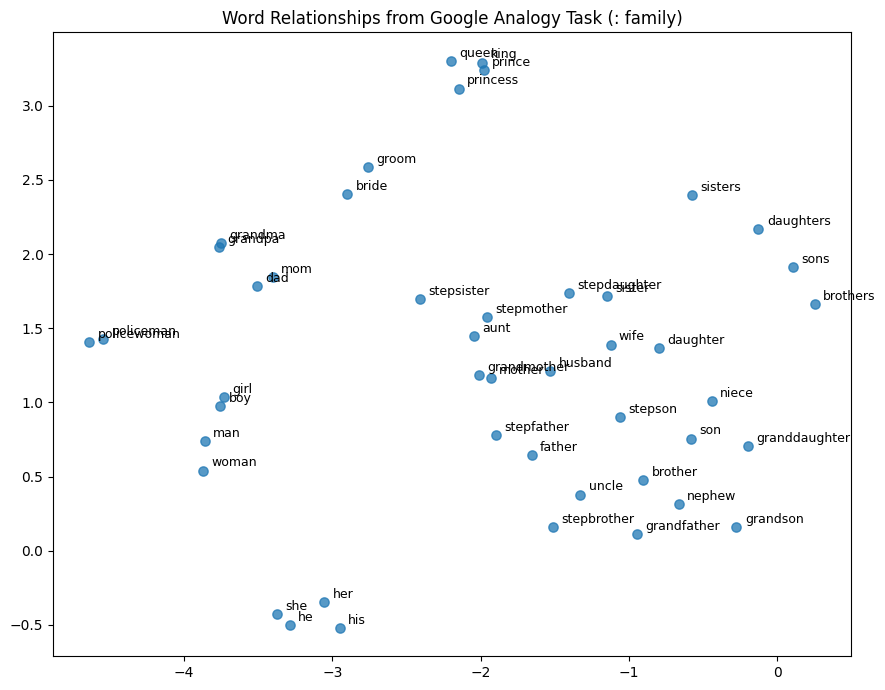

In [29]:
from sklearn.manifold import TSNE


# Collect words from Google Analogy dataset
SUB_CATEGORY = ": family"

# TODO7: Plot t-SNE for the words in the SUB_CATEGORY `: family`

subset = data[data["SubCategory"] == SUB_CATEGORY]["Question"]

words = sorted({token.lower() for analogy in subset for token in analogy.split()})

vectors, labels, missing = [], [], []
for word in words:
    if word in custom_vectors.key_to_index:
        vectors.append(custom_vectors[word])
        labels.append(word)
    else:
        missing.append(word)

if missing:
    print(f"Skipped {len(missing)} OOV words:", ", ".join(missing))

if len(vectors) < 2:
    raise ValueError("Not enough in-vocabulary words to plot t-SNE.")

vectors_np = np.vstack(vectors)
coords = TSNE(
    n_components=2,
    perplexity=min(30, len(vectors_np) - 1),
    random_state=0,
    init="pca",
    learning_rate="auto",
).fit_transform(vectors_np)

plt.figure(figsize=(9, 7))
plt.scatter(coords[:, 0], coords[:, 1], s=45, alpha=0.75)

for (x, y), label in zip(coords, labels):
    plt.annotate(label, (x, y), textcoords="offset points", xytext=(6, 3), fontsize=9)

plt.title("Word Relationships from Google Analogy Task (: family)")
plt.tight_layout()
plt.savefig("word_relationships_custom.png", bbox_inches="tight")
plt.show()

In [1]:
# Q2 Evaluation: Compare 5%, 10%, and 20% sampling rates
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from tqdm.auto import tqdm

# Load the questions data
data = pd.read_csv("questions-words.csv")

# Define model paths
model_configs = {
    "5%": "/Users/leonardo/Workspace/nthu-2025-fall-natural-language-processing/hw1/models/5/custom_word2vec.model",
    "10%": "/Users/leonardo/Workspace/nthu-2025-fall-natural-language-processing/hw1/models/10/custom_word2vec.model",
    "20%": "/Users/leonardo/Workspace/nthu-2025-fall-natural-language-processing/hw1/models/20/custom_word2vec.model",
}

def calculate_accuracy(gold: np.ndarray, pred: np.ndarray) -> float:
    return np.mean(gold == pred)

def evaluate_model(model_path, sampling_rate):
    """Evaluate a single model and return results"""
    print(f"\n{'='*60}")
    print(f"Evaluating model trained with {sampling_rate} sampling")
    print(f"{'='*60}")
    
    # Load model
    model = Word2Vec.load(model_path)
    vectors = model.wv
    
    # Get predictions
    preds = []
    golds = []
    
    for analogy in tqdm(data["Question"], desc=f"Predicting ({sampling_rate})"):
        word_a, word_b, word_c, word_d = [w.lower() for w in analogy.split()]
        golds.append(word_d)
        
        if any(word not in vectors.key_to_index for word in (word_a, word_b, word_c)):
            preds.append(None)
            continue
        
        prediction = vectors.most_similar(
            positive=[word_b, word_c], 
            negative=[word_a], 
            topn=1
        )[0][0]
        preds.append(prediction)
    
    # Calculate accuracies
    golds_np = np.array(golds, dtype=object)
    preds_np = np.array(preds, dtype=object)
    
    results = {
        'sampling_rate': sampling_rate,
        'vocab_size': len(vectors),
        'categories': {},
        'subcategories': {}
    }
    
    # Overall accuracy
    overall_acc = calculate_accuracy(golds_np, preds_np)
    results['overall'] = overall_acc * 100
    print(f"\nOverall Accuracy: {overall_acc * 100:.2f}%")
    print(f"Vocabulary Size: {len(vectors):,}")
    
    # Category accuracies
    print(f"\n--- Category Accuracies ---")
    for category in data["Category"].unique():
        mask = data["Category"] == category
        acc_cat = calculate_accuracy(golds_np[mask], preds_np[mask])
        results['categories'][category] = acc_cat * 100
        print(f"{category}: {acc_cat * 100:.2f}%")
    
    # Sub-category accuracies
    print(f"\n--- Sub-Category Accuracies ---")
    for sub_category in data["SubCategory"].unique():
        mask = data["SubCategory"] == sub_category
        acc_subcat = calculate_accuracy(golds_np[mask], preds_np[mask])
        results['subcategories'][sub_category] = acc_subcat * 100
        print(f"{sub_category}: {acc_subcat * 100:.2f}%")
    
    return results

# Evaluate all models
all_results = {}
for sampling_rate, model_path in model_configs.items():
    all_results[sampling_rate] = evaluate_model(model_path, sampling_rate)

# Create comparison summary
print(f"\n\n{'='*80}")
print("COMPARISON SUMMARY")
print(f"{'='*80}")

# Overall comparison
print(f"\n{'Sampling Rate':<15} {'Vocab Size':<15} {'Overall':<12} {'Semantic':<12} {'Syntactic':<12}")
print("-" * 80)
for rate in ["5%", "10%", "20%"]:
    r = all_results[rate]
    print(f"{rate:<15} {r['vocab_size']:<15,} {r['overall']:<12.2f} "
          f"{r['categories']['Semantic']:<12.2f} {r['categories']['Syntactic']:<12.2f}")

# Detailed subcategory comparison
print(f"\n{'Sub-Category':<35} {'5%':<12} {'10%':<12} {'20%':<12} {'Improvement':<12}")
print("-" * 80)
for subcat in data["SubCategory"].unique():
    acc_5 = all_results["5%"]['subcategories'][subcat]
    acc_10 = all_results["10%"]['subcategories'][subcat]
    acc_20 = all_results["20%"]['subcategories'][subcat]
    improvement = acc_20 - acc_5
    print(f"{subcat:<35} {acc_5:<12.2f} {acc_10:<12.2f} {acc_20:<12.2f} {improvement:+.2f}")

/opt/homebrew/Caskroom/mambaforge/base/envs/nlp_hw1/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Evaluating model trained with 5% sampling


Predicting (5%): 100%|██████████| 19544/19544 [01:50<00:00, 177.18it/s]



Overall Accuracy: 51.88%
Vocabulary Size: 450,347

--- Category Accuracies ---
Semantic: 64.31%
Syntactic: 41.55%

--- Sub-Category Accuracies ---
: capital-common-countries: 93.48%
: capital-world: 78.36%
: currency: 11.09%
: city-in-state: 48.64%
: family: 77.08%
: gram1-adjective-to-adverb: 11.90%
: gram2-opposite: 11.58%
: gram3-comparative: 52.03%
: gram4-superlative: 20.86%
: gram5-present-participle: 34.94%
: gram6-nationality-adjective: 85.80%
: gram7-past-tense: 40.45%
: gram8-plural: 44.59%
: gram9-plural-verbs: 37.93%

Evaluating model trained with 10% sampling


Predicting (10%): 100%|██████████| 19544/19544 [02:52<00:00, 113.41it/s]



Overall Accuracy: 53.36%
Vocabulary Size: 703,054

--- Category Accuracies ---
Semantic: 65.69%
Syntactic: 43.12%

--- Sub-Category Accuracies ---
: capital-common-countries: 92.49%
: capital-world: 81.23%
: currency: 9.12%
: city-in-state: 48.07%
: family: 82.61%
: gram1-adjective-to-adverb: 14.52%
: gram2-opposite: 16.01%
: gram3-comparative: 47.52%
: gram4-superlative: 24.78%
: gram5-present-participle: 35.70%
: gram6-nationality-adjective: 87.18%
: gram7-past-tense: 43.40%
: gram8-plural: 45.57%
: gram9-plural-verbs: 41.72%

Evaluating model trained with 20% sampling


Predicting (20%): 100%|██████████| 19544/19544 [05:54<00:00, 55.13it/s]  


Overall Accuracy: 53.83%
Vocabulary Size: 1,081,457

--- Category Accuracies ---
Semantic: 65.96%
Syntactic: 43.75%

--- Sub-Category Accuracies ---
: capital-common-countries: 90.71%
: capital-world: 82.98%
: currency: 11.89%
: city-in-state: 45.48%
: family: 81.42%
: gram1-adjective-to-adverb: 18.25%
: gram2-opposite: 14.66%
: gram3-comparative: 47.60%
: gram4-superlative: 22.28%
: gram5-present-participle: 33.90%
: gram6-nationality-adjective: 86.93%
: gram7-past-tense: 42.76%
: gram8-plural: 51.35%
: gram9-plural-verbs: 44.48%


COMPARISON SUMMARY

Sampling Rate   Vocab Size      Overall      Semantic     Syntactic   
--------------------------------------------------------------------------------
5%              450,347         51.88        64.31        41.55       
10%             703,054         53.36        65.69        43.12       
20%             1,081,457       53.83        65.96        43.75       

Sub-Category                        5%           10%          20%         

In [ ]:
# Q4 : Retrieve top 5 similar words with basic noise filtering
from gensim.models import Word2Vec

path_to_model = "/Users/leonardo/Workspace/nthu-2025-fall-natural-language-processing/hw1/models/20/custom_word2vec.model"
custom_model = Word2Vec.load(path_to_model)
vectors = custom_model.wv

selected_words = ["king", "woman", "good", "run", "computer"]


def is_noisy(token: str) -> bool:
    # Simple heuristic filters
    if len(token) > 20:
        return True
    if any(ch.isdigit() for ch in token):
        return True
    return False


def top_similar_clean(word, topn=5, search_pool=60, restrict_vocab=30000):
    raw = vectors.most_similar(
        word,
        topn=search_pool,
        restrict_vocab=restrict_vocab,  # limit to most frequent words
    )
    cleaned = [(w, s) for w, s in raw if not is_noisy(w)]
    return cleaned[:topn]


for word in selected_words:
    if word not in vectors.key_to_index:
        print(f"'{word}' not in vocabulary.\n")
        continue
    freq = vectors.get_vecattr(word, "count")
    neighbors = top_similar_clean(word)
    print(f"Top similar to '{word}' (freq={freq}):")
    for w, score in neighbors:
        w_freq = vectors.get_vecattr(w, "count")
        print(f"  {w:<15} {score:.4f}  (freq={w_freq})")
    print()

Top similar to 'king' (freq=253620):
  prince          0.8248  (freq=93375)
  queen           0.7622  (freq=93096)
  throne          0.7466  (freq=18572)
  monarch         0.7292  (freq=9852)
  princess        0.6996  (freq=39134)

Top similar to 'woman' (freq=115803):
  man             0.8127  (freq=239445)
  girl            0.7827  (freq=77093)
  person          0.7516  (freq=93626)
  child           0.6715  (freq=95830)
  herself         0.6523  (freq=41080)

Top similar to 'good' (freq=137432):
  decent          0.7718  (freq=2935)
  always          0.7463  (freq=61122)
  pretty          0.7374  (freq=12660)
  bad             0.7294  (freq=46519)
  tough           0.7278  (freq=8134)

Top similar to 'run' (freq=160493):
  ran             0.7323  (freq=73527)
  winning         0.6599  (freq=104295)
  walk            0.6511  (freq=31614)
  go              0.6500  (freq=126116)
  start           0.6435  (freq=106862)

Top similar to 'computer' (freq=63359):
  computers       0.8317  (